# Appendix A | Data Exploration

---

# Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.preprocessing.transform import *

In [2]:
# import warnings
# warnings.filterwarnings('ignore')

# Defaults

In [3]:
pd.set_option("display.float_format", "{:.6f}".format)
plt.rcParams['figure.figsize'] = (6.4, 4.8)
TARGET='Life Ladder'
hist_bins = 30

# Fetch Data

In [4]:
train_path = '/Q1_OLD/DATA/happiness_data_train.csv'
train_df = read_csv_to_df(path=train_path)

In [5]:
train_df.info()
train_df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1559 entries, 0 to 1558
Data columns (total 9 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Life Ladder                       1559 non-null   float64
 1   Log GDP per capita                1533 non-null   float64
 2   Social support                    1549 non-null   float64
 3   Healthy life expectancy at birth  1522 non-null   float64
 4   Freedom to make life choices      1537 non-null   float64
 5   Generosity                        1488 non-null   float64
 6   Perceptions of corruption         1473 non-null   float64
 7   Positive affect                   1542 non-null   float64
 8   Negative affect                   1545 non-null   float64
dtypes: float64(9)
memory usage: 109.7 KB


,count,mean,std,min,25%,50%,75%,max
Life Ladder,1559.000000,5.469321,1.113280,2.375000,4.649500,5.374000,6.272500,8.019000
Log GDP per capita,1533.000000,9.362995,1.160240,6.635000,8.460000,9.456000,10.332000,11.648000
Social support,1549.000000,0.812689,0.118762,0.290000,0.753000,0.835000,0.905000,0.987000
Healthy life expectancy at birth,1522.000000,63.331680,7.478307,32.300000,58.340000,65.180000,68.535000,77.100000
Freedom to make life choices,1537.000000,0.741882,0.142326,0.260000,0.646000,0.763000,0.855000,0.985000
Generosity,1488.000000,0.000343,0.163385,-0.335000,-0.113000,-0.025000,0.091000,0.698000
Perceptions of corruption,1473.000000,0.748248,0.186708,0.035000,0.691000,0.804000,0.873000,0.983000
Positive affect,1542.000000,0.708551,0.108029,0.322000,0.623000,0.721000,0.798000,0.944000
Negative affect,1545.000000,0.267644,0.084431,0.083000,0.206000,0.258000,0.319000,0.705000


In [6]:
train_df.isna().sum().sort_values()

Life Ladder                          0
Social support                      10
Negative affect                     14
Positive affect                     17
Freedom to make life choices        22
Log GDP per capita                  26
Healthy life expectancy at birth    37
Generosity                          71
Perceptions of corruption           86
dtype: int64

## Combined Correlation

In [42]:
corr_matrix = train_df.corr()
corr_matrix

,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
Life Ladder,1.000000,0.786712,0.703878,0.750773,0.529819,0.194970,-0.427562,0.534640,-0.301821
Log GDP per capita,0.786712,1.000000,0.696893,0.850872,0.359674,-0.006162,-0.341493,0.296017,-0.215581
Social support,0.703878,0.696893,1.000000,0.621460,0.420372,0.062367,-0.225764,0.424982,-0.403880
Healthy life expectancy at birth,0.750773,0.850872,0.621460,1.000000,0.381830,0.019077,-0.322159,0.311821,-0.137307
Freedom to make life choices,0.529819,0.359674,0.420372,0.381830,1.000000,0.327079,-0.480826,0.614398,-0.272536
Generosity,0.194970,-0.006162,0.062367,0.019077,0.327079,1.000000,-0.276108,0.377166,-0.106673
Perceptions of corruption,-0.427562,-0.341493,-0.225764,-0.322159,-0.480826,-0.276108,1.000000,-0.300299,0.277781
Positive affect,0.534640,0.296017,0.424982,0.311821,0.614398,0.377166,-0.300299,1.000000,-0.357850
Negative affect,-0.301821,-0.215581,-0.403880,-0.137307,-0.272536,-0.106673,0.277781,-0.357850,1.000000


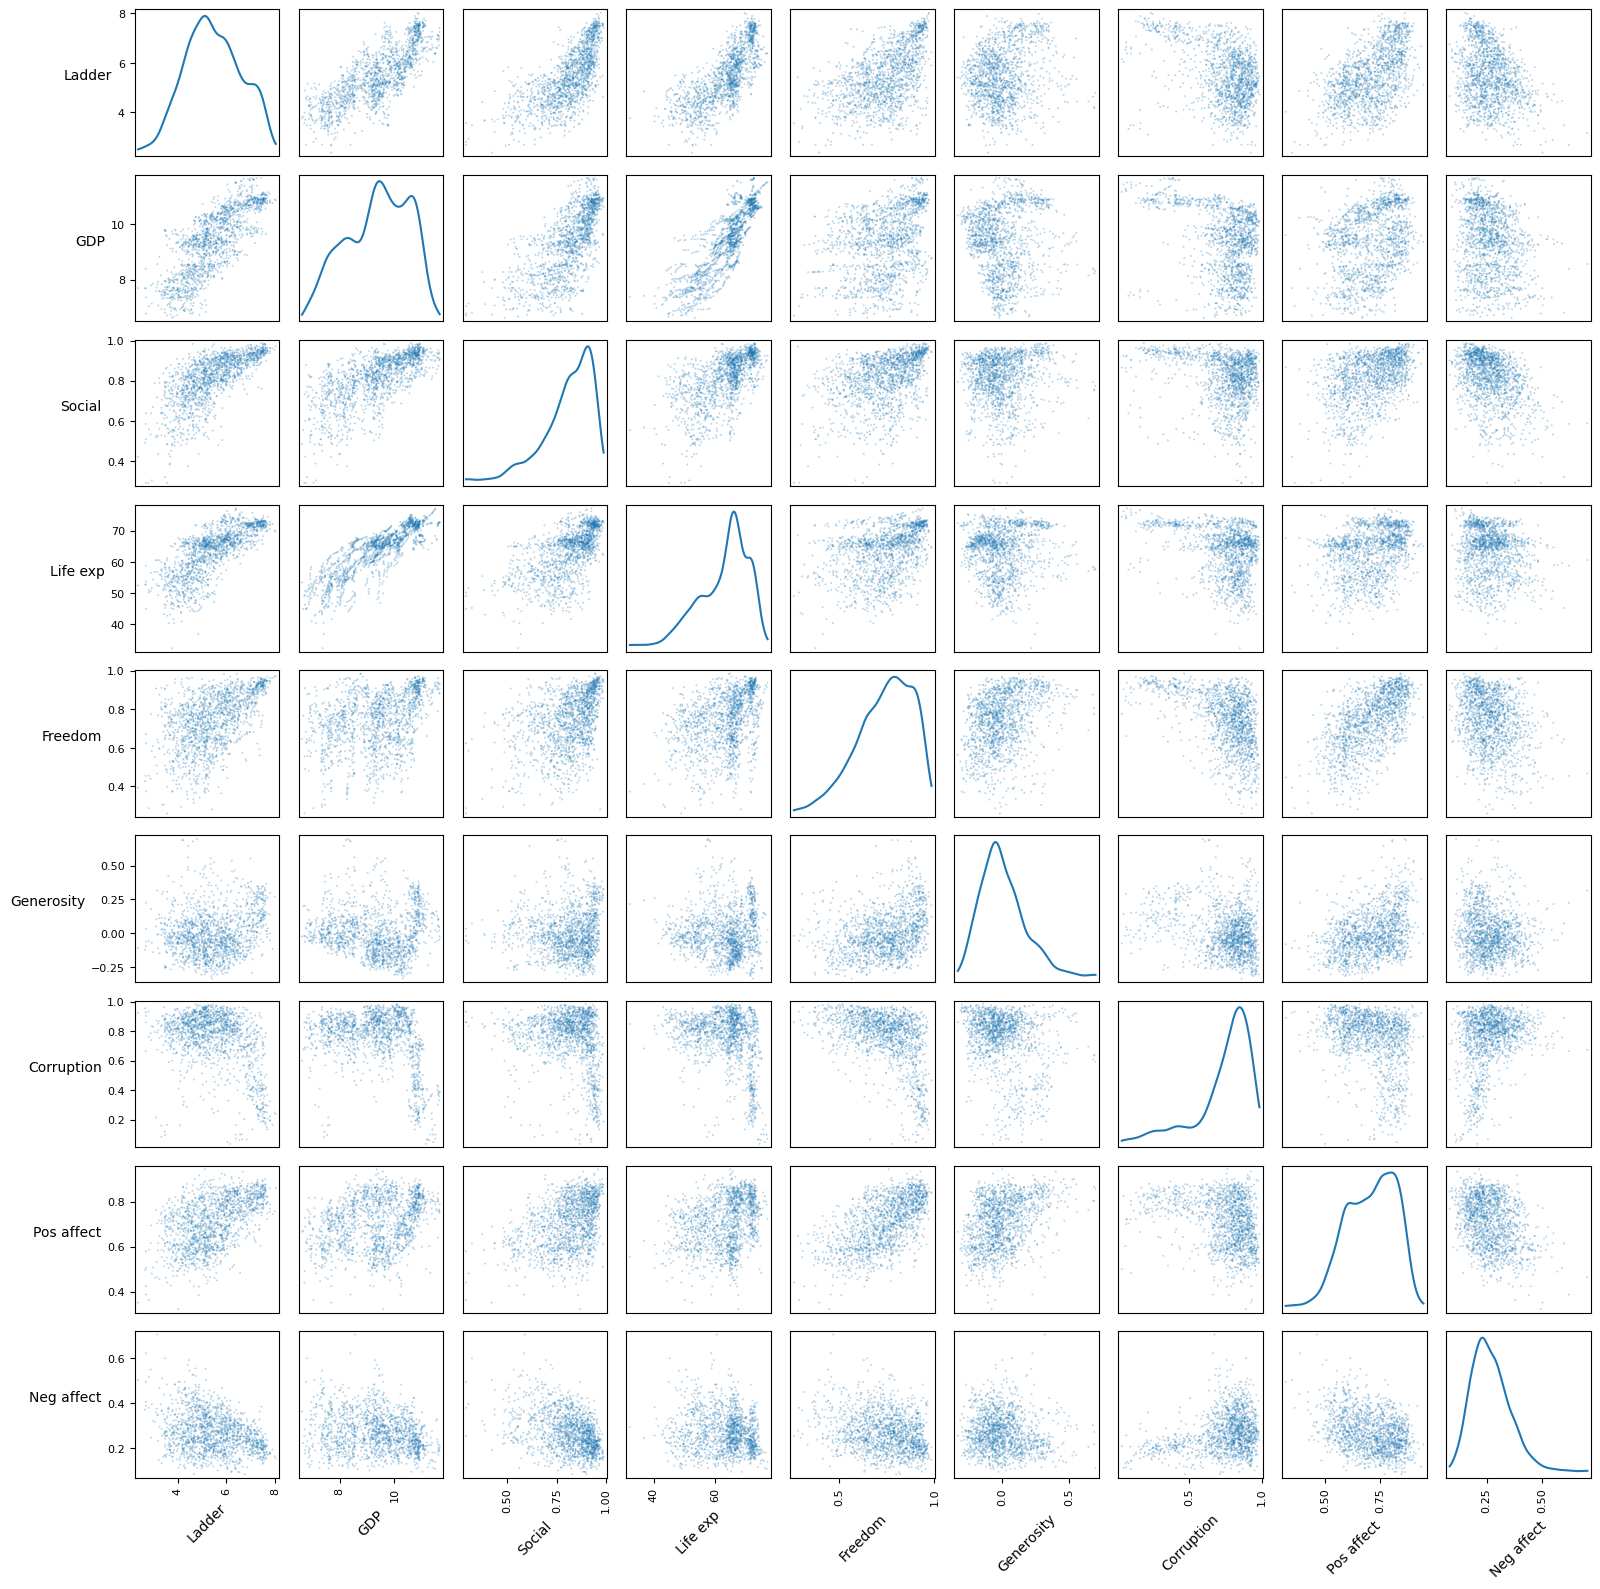

In [43]:
from pandas.plotting import scatter_matrix

train_df_short_names = train_df.copy()
short_names = {
    "Life Ladder": "Ladder",
    "Log GDP per capita": "GDP",
    "Social support": "Social",
    "Healthy life expectancy at birth": "Life exp",
    "Freedom to make life choices": "Freedom",
    "Generosity": "Generosity",
    "Perceptions of corruption": "Corruption",
    "Positive affect": "Pos affect",
    "Negative affect": "Neg affect",
}

plot_df = train_df.rename(columns=short_names)

axes = scatter_matrix(
    plot_df,
    figsize=(16, 16),   # much bigger canvas
    alpha=0.3,          # see where points are dense
    s=8,                # smaller markers
    diagonal="kde",     # smooth density instead of histogram (optional)
)

# Rotate labels so they're horizontal and readable
for ax in axes.flatten():
    ax.xaxis.label.set_rotation(45)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_ha("right")

plt.tight_layout()
plt.show()

### Notes / Observations
- Ranking by strength of link to Life Ladder:
  - Strong: GDP (0.79), Life expectancy (0.75), Social support (0.70)
  - Moderate: Positive affect (0.53), Freedom (0.53), Corruption (-0.43)
  - Weak: Negative affect (-0.30), Generosity (0.19)
- Every direction makes intuitive sense: good things (wealth, health, support, freedom, joy) rise with happiness, and bad things (corruption, worry) fall with it.
- Two groups of features move together:
  - "Wealth and development": GDP, Life expectancy and Social support (r between 0.62 and 0.85).
  - "Freedom and mood": Freedom, Positive affect and (inversely) Corruption (r between 0.48 and 0.61).
- Generosity and Negative affect are only loosely tied to everything else.
- The GDP vs Life exp panel in the scatter matrix shows thin diagonal streaks. These look like the same country tracked over several years, which suggests the rows are not fully independent.
- 185 rows (about 12%) have at least one missing value, even though no single feature is missing more than 5.5%.